## 1. Setup

# Weather-Driven Forecasting of Ceylon Tea Production - Ensemble Learning
**Can rainfall, temperature and sunshine in Sri Lanka's tea-growing regions help predict tea production? Bagging vs Boosting vs Stacking vs Hybrid models.**

**Goal:** Predict monthly made-tea production (million kg) for **High, Medium and Low grown** tea using (1) recent production and (2) the weather in each elevation's tea-growing regions, and compare 10 models from 7 families.

| Family | Models |
|---|---|
| Baseline | Seasonal naïve (same month last year) |
| Bagging | Random Forest, Extra Trees |
| Boosting | Gradient Boosting, LightGBM, CatBoost |
| Neural network | ANN (MLP) |
| Stacking | RF + GB + LightGBM + CatBoost → Ridge meta-learner |
| Time series | SARIMA |
| Hybrid | SARIMA + Random Forest (RF learns what SARIMA misses, using weather) |

**Datasets (Sri Lanka only):**
1. **Tea production** - monthly made-tea production by elevation (High, Medium, Low, Green), **Jan 2015 – Dec 2025** (132 months). Source: Sri Lanka Tea Board figures as published in Forbes & Walker Tea Brokers' annual production summaries (forbestea.com). Every month was checked: High + Medium + Low + Green = Total (one digit-swap in Feb 2015 Low grown was corrected using the published total).
2. **Daily weather for 8 locations in Sri Lanka's tea-growing regions** - **≈ 33,000 daily records** (Oct 2014 – Jan 2026) of rainfall, rain hours, temperature (mean/max/min), sunshine, solar radiation and evapotranspiration, from the Open-Meteo historical weather archive (ERA5 reanalysis).

**Why these 8 locations?** The Sri Lanka Tea Board divides tea cultivation into seven official tea-growing regions: Nuwara Eliya, Dimbula, Uva and Uda Pussellawa (high grown), Kandy (mid grown), and Sabaragamuwa and Ruhuna (low grown). A weather archive works with map points, so we picked a well-known tea town in each region (two where the region is large) and averaged the weather by elevation:

| Location | Official tea region | Elevation | Why chosen |
|---|---|---|---|
| Nuwara Eliya | Nuwara Eliya | High | Main town of the highest tea region |
| Hatton | Dimbula | High | Centre of the Dimbula (Hatton–Dickoya) estates on the western slopes |
| Bandarawela | Uva | High | Main Uva tea town; Uva is on the eastern side and gets a different monsoon |
| Kandy | Kandy | Medium | Centre of the mid-grown Kandy region |
| Matale | Kandy | Medium | Mid-grown estates north of Kandy |
| Ratnapura | Sabaragamuwa | Low | Main town of the largest low-grown region |
| Galle | Ruhuna | Low | Low-grown estates of the south |
| Deniyaya | Ruhuna | Low | Wetter inland Ruhuna estates in the Matara hills |

Uda Pussellawa is a small region next to Nuwara Eliya, so its weather is already represented by Nuwara Eliya.


> **AI-use declaration:** The notebook code and dashboard application (`app.py`) were developed with assistance from Claude (Anthropic), an AI tool permitted by the lecturer. I am responsible for the dataset selection, experimental design, result verification, and interpretation, and I have personally reviewed all the code and outputs.

In [1]:
!pip -q install catboost
import io, os, json, time, shutil, warnings, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, lightgbm, catboost, statsmodels, joblib
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
ELEVS = ['High','Medium','Low']
VERSIONS = {'scikit-learn': sklearn.__version__, 'lightgbm': lightgbm.__version__,
            'catboost': catboost.__version__, 'statsmodels': statsmodels.__version__}
print(VERSIONS)

{'scikit-learn': '1.6.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'statsmodels': '0.15.0'}


## 2. Dataset 1 - monthly tea production by elevation (2015–2025)
Values in kg (embedded so the notebook runs anywhere). We work in **million kg (Mn kg)**.

In [2]:
PROD_CSV = """Date,Year,Month,MonthName,High,Medium,Low,Green,Total
2015-01-01,2015,1,Jan,4849077,2957245,15211511,243110,23260943
2015-02-01,2015,2,Feb,6331313,4044553,14805957,274253,25456076
2015-03-01,2015,3,Mar,6999639,4374406,18599099,298233,30271377
2015-04-01,2015,4,Apr,8468268,5304315,17739620,263685,31775888
2015-05-01,2015,5,May,8441936,4944511,18634005,219149,32239601
2015-06-01,2015,6,Jun,7576784,4387189,16702488,251927,28918388
2015-07-01,2015,7,Jul,5066192,3459183,17035625,228798,25789798
2015-08-01,2015,8,Aug,4601543,3286085,17958140,194650,26040418
2015-09-01,2015,9,Sep,5876746,3764321,17013927,225264,26880258
2015-10-01,2015,10,Oct,6172270,4037163,16267757,257509,26734699
2015-11-01,2015,11,Nov,5864729,3526230,15606385,206325,25203669
2015-12-01,2015,12,Dec,5397637,3045044,14882785,192616,23518082
2016-01-01,2016,1,Jan,5491060,3471562,15905940,213130,25081692
2016-02-01,2016,2,Feb,5344269,3335303,14034014,186869,22900455
2016-03-01,2016,3,Mar,5223124,3379427,13285462,178523,22066536
2016-04-01,2016,4,Apr,6133069,4183206,15922715,232435,26471425
2016-05-01,2016,5,May,8195136,4812529,17318117,301347,30627129
2016-06-01,2016,6,Jun,4838072,3726874,16582355,213000,25360301
2016-07-01,2016,7,Jul,4408388,3137375,13606380,173515,21325658
2016-08-01,2016,8,Aug,3958062,3066708,15835141,151224,23011135
2016-09-01,2016,9,Sep,3900690,2849648,12904251,154673,19809262
2016-10-01,2016,10,Oct,3348898,2230265,12872368,114087,18565618
2016-11-01,2016,11,Nov,5720632,3629131,17783343,179677,27312783
2016-12-01,2016,12,Dec,6078549,4278032,16577572,245543,27179696
2017-01-01,2017,1,Jan,4465111,2669857,13967493,153290,21255751
2017-02-01,2017,2,Feb,3939102,2624078,11768362,130761,18462303
2017-03-01,2017,3,Mar,5887709,4289306,15948477,308287,26433779
2017-04-01,2017,4,Apr,8239094,5046403,19196904,307692,32790093
2017-05-01,2017,5,May,7479702,4766500,16904409,308385,29458996
2017-06-01,2017,6,Jun,4978254,3762158,18087371,274723,27102506
2017-07-01,2017,7,Jul,4771559,3594741,17039747,190811,25596858
2017-08-01,2017,8,Aug,4056019,3234950,17182163,210656,24683788
2017-09-01,2017,9,Sep,4666787,3466540,17128793,197702,25459822
2017-10-01,2017,10,Oct,4839388,3560133,16853762,215325,25468608
2017-11-01,2017,11,Nov,4965530,3437604,16207432,162824,24773390
2017-12-01,2017,12,Dec,4466414,3272261,15653674,111124,23503473
2018-01-01,2018,1,Jan,5014906,3144692,15948742,162632,24270972
2018-02-01,2018,2,Feb,4907112,3032408,12920071,196710,21056301
2018-03-01,2018,3,Mar,6114478,3907263,18181272,308287,28511300
2018-04-01,2018,4,Apr,7266033,4713901,15672718,258775,27911427
2018-05-01,2018,5,May,7297735,5223576,20039935,259584,32820830
2018-06-01,2018,6,Jun,4694841,3455226,14656770,224565,23031402
2018-07-01,2018,7,Jul,3708686,3499062,16471766,166511,23846025
2018-08-01,2018,8,Aug,3590519,2934784,14663238,181527,21370068
2018-09-01,2018,9,Sep,3934082,3144764,12064693,187407,19330946
2018-10-01,2018,10,Oct,7038897,4958844,17365284,253737,29616762
2018-11-01,2018,11,Nov,4736565,3767643,16035125,184429,24723762
2018-12-01,2018,12,Dec,4961092,3740608,17077492,224980,26004172
2019-01-01,2019,1,Jan,4714358,3570616,14703300,219746,23208020
2019-02-01,2019,2,Feb,4038996,3253887,14075132,227088,21595103
2019-03-01,2019,3,Mar,5535249,4223000,18143598,252638,28154485
2019-04-01,2019,4,Apr,5220584,3631563,14546922,224105,23623174
2019-05-01,2019,5,May,7958519,5582254,20239749,328647,34109169
2019-06-01,2019,6,Jun,6056045,4340651,16518687,280415,27195798
2019-07-01,2019,7,Jul,5036959,3652990,16377533,203542,25271024
2019-08-01,2019,8,Aug,4757253,3714107,17401938,211096,26084394
2019-09-01,2019,9,Sep,3728812,3123892,14740134,144488,21737326
2019-10-01,2019,10,Oct,3404692,3188062,14051674,169032,20813460
2019-11-01,2019,11,Nov,6362005,4086027,13275901,240092,23964025
2019-12-01,2019,12,Dec,4195940,2782789,14779627,135463,21893819
2020-01-01,2020,1,Jan,5000699,3447598,13326003,164633,21938933
2020-02-01,2020,2,Feb,4366890,3314138,10100662,166708,17948398
2020-03-01,2020,3,Mar,3295665,2563918,7306497,114632,13280712
2020-04-01,2020,4,Apr,3964026,2942039,13284895,74008,20264968
2020-05-01,2020,5,May,6660337,5892923,15670300,134572,28358132
2020-06-01,2020,6,Jun,7157374,4199221,15323235,167801,26847631
2020-07-01,2020,7,Jul,5794315,4164602,16144669,175826,26279412
2020-08-01,2020,8,Aug,4047227,3333906,14869963,176107,22427203
2020-09-01,2020,9,Sep,4123627,3326869,14260280,199752,21910528
2020-10-01,2020,10,Oct,4451673,3387392,15400615,217718,23457398
2020-11-01,2020,11,Nov,5391251,4016229,15178342,221205,24807027
2020-12-01,2020,12,Dec,6420313,4575468,17322787,185884,28504452
2021-01-01,2021,1,Jan,4716756,3250149,14911473,166819,23045197
2021-02-01,2021,2,Feb,4484149,3529846,14200275,165127,22379397
2021-03-01,2021,3,Mar,6349619,4884624,16930375,246372,28410990
2021-04-01,2021,4,Apr,6765985,5392857,17234904,193762,29587508
2021-05-01,2021,5,May,7069398,5801776,17282615,222031,30375820
2021-06-01,2021,6,Jun,5774279,4352372,15556888,254153,25937692
2021-07-01,2021,7,Jul,5669713,4675307,15565360,254586,26164966
2021-08-01,2021,8,Aug,4857931,3734310,14864098,243754,23700093
2021-09-01,2021,9,Sep,3980906,3560430,14782095,240592,22564023
2021-10-01,2021,10,Oct,4653703,3902276,15205413,235539,23996931
2021-11-01,2021,11,Nov,4063313,3137608,12647820,154759,20003500
2021-12-01,2021,12,Dec,4415105,3102325,12705183,194882,20417495
2022-01-01,2022,1,Jan,5331417,3785541,13475779,224477,22817214
2022-02-01,2022,2,Feb,4247649,2758586,11009385,147839,18163459
2022-03-01,2022,3,Mar,4966198,3423601,13508837,117253,22015889
2022-04-01,2022,4,Apr,5642913,4117750,13052379,96548,22909590
2022-05-01,2022,5,May,6323965,4722178,14844241,148907,26039291
2022-06-01,2022,6,Jun,3998387,2891558,13126936,131884,20148765
2022-07-01,2022,7,Jul,4045305,2817891,12877521,120166,19860882
2022-08-01,2022,8,Aug,3359406,2403992,12420299,93196,18276893
2022-09-01,2022,9,Sep,4651987,3430515,12708395,172439,20963336
2022-10-01,2022,10,Oct,3857393,2988783,11736445,168942,18751563
2022-11-01,2022,11,Nov,4247020,3005628,12805859,186407,20244914
2022-12-01,2022,12,Dec,4231400,2828002,12274848,167152,19501402
2023-01-01,2023,1,Jan,3547301,2424351,12338331,161634,18471618
2023-02-01,2023,2,Feb,4193821,3012439,11360354,190435,18757049
2023-03-01,2023,3,Mar,4840981,3492881,13703631,248211,22285704
2023-04-01,2023,4,Apr,6301029,4421631,14290453,224694,25237807
2023-05-01,2023,5,May,7140569,4715763,14760035,208724,26825090
2023-06-01,2023,6,Jun,5551193,3972889,13403471,160922,23088476
2023-07-01,2023,7,Jul,4426982,3266402,13733747,140307,21567438
2023-08-01,2023,8,Aug,4112438,2925308,11152655,167691,18358092
2023-09-01,2023,9,Sep,4157024,2975677,11567172,203571,18903445
2023-10-01,2023,10,Oct,4152051,3815752,14829023,203433,23000259
2023-11-01,2023,11,Nov,4520668,3366724,11704128,193155,19784674
2023-12-01,2023,12,Dec,4467996,2902275,12257920,180806,19808997
2024-01-01,2024,1,Jan,3475827,2539587,12566699,147346,18729459
2024-02-01,2024,2,Feb,4420844,3563853,11826047,185270,19996014
2024-03-01,2024,3,Mar,4854723,3766513,10768968,176731,19566935
2024-04-01,2024,4,Apr,4510412,3483269,13319782,151145,21464608
2024-05-01,2024,5,May,5785865,4314602,14260736,188529,24549732
2024-06-01,2024,6,Jun,4815161,4272382,13708683,228160,23024387
2024-07-01,2024,7,Jul,5434639,3938173,13281824,236930,22891566
2024-08-01,2024,8,Aug,3717694,3701427,13679673,183145,21281940
2024-09-01,2024,9,Sep,4596353,4107689,15239510,189695,24133247
2024-10-01,2024,10,Oct,4011626,3525709,13432458,179542,21149334
2024-11-01,2024,11,Nov,5013425,4208283,12876870,203616,22302194
2024-12-01,2024,12,Dec,4489069,3679822,13355733,190307,21714931
2025-01-01,2025,1,Jan,4579128,3395023,13297657,191206,21463013
2025-02-01,2025,2,Feb,3359208,2522925,9555790,158205,15596129
2025-03-01,2025,3,Mar,5550715,4821600,13819257,237211,24428783
2025-04-01,2025,4,Apr,6237546,5286384,14648183,220423,26392537
2025-05-01,2025,5,May,5840392,4980563,14329661,214702,25365319
2025-06-01,2025,6,Jun,4159203,3888081,13455861,184460,21687605
2025-07-01,2025,7,Jul,3871749,3654570,13644032,188885,21359236
2025-08-01,2025,8,Aug,3608275,3172507,12714066,184319,19679166
2025-09-01,2025,9,Sep,4848684,4035664,13103504,188406,22176258
2025-10-01,2025,10,Oct,3789861,3471935,14343676,176195,21781667
2025-11-01,2025,11,Nov,4587714,3890259,12778913,192855,21449741
2025-12-01,2025,12,Dec,4513977,3536134,13128737,196710,21375558"""
tea = pd.read_csv(io.StringIO(PROD_CSV), parse_dates=['Date'])
assert ((tea.High + tea.Medium + tea.Low + tea.Green - tea.Total).abs() <= 5).all()   # every month adds up
print(tea.shape, '| years:', tea.Year.min(), '-', tea.Year.max())
tea.head()

(132, 9) | years: 2015 - 2025


,Date,Year,Month,MonthName,High,Medium,Low,Green,Total
0,2015-01-01,2015,1,Jan,4849077,2957245,15211511,243110,23260943
1,2015-02-01,2015,2,Feb,6331313,4044553,14805957,274253,25456076
2,2015-03-01,2015,3,Mar,6999639,4374406,18599099,298233,30271377
3,2015-04-01,2015,4,Apr,8468268,5304315,17739620,263685,31775888
4,2015-05-01,2015,5,May,8441936,4944511,18634005,219149,32239601


## 3. Dataset 2 - daily weather at 8 locations across the tea-growing regions (Open-Meteo archive)
Downloads daily weather for each location (no API key needed). The result is cached to a CSV so re-runs don't download again.

In [3]:
LOCATIONS = {   # location: (elevation, official tea region, latitude, longitude)
    'Nuwara Eliya': ('High', 'Nuwara Eliya', 6.9708, 80.7829), 'Hatton': ('High', 'Dimbula', 6.8916, 80.5955),
    'Bandarawela': ('High', 'Uva', 6.8259, 80.9982),
    'Kandy': ('Medium', 'Kandy', 7.2906, 80.6337), 'Matale': ('Medium', 'Kandy', 7.4675, 80.6234),
    'Ratnapura': ('Low', 'Sabaragamuwa', 6.6828, 80.3992), 'Galle': ('Low', 'Ruhuna', 6.0535, 80.2210),
    'Deniyaya': ('Low', 'Ruhuna', 6.3427, 80.5585)}
DAILY_VARS = ['precipitation_sum','precipitation_hours','temperature_2m_mean','temperature_2m_max','temperature_2m_min',
              'sunshine_duration','shortwave_radiation_sum','et0_fao_evapotranspiration']
WEATHER_FILE = 'srilanka_tea_regions_weather_daily.csv'

def download(name, lat, lon):
    params = dict(latitude=lat, longitude=lon, start_date='2014-10-01', end_date='2026-01-31',
                  daily=','.join(DAILY_VARS), timezone='Asia/Colombo')
    for attempt in range(5):
        r = requests.get('https://archive-api.open-meteo.com/v1/archive', params=params, timeout=90)
        if r.ok: break
        time.sleep(10 * (attempt + 1))
    r.raise_for_status()
    d = pd.DataFrame(r.json()['daily']).rename(columns={'time':'date'})
    d.insert(1, 'location', name); d.insert(2, 'region', LOCATIONS[name][1]); d.insert(3, 'elevation', LOCATIONS[name][0])
    return d

if os.path.exists(WEATHER_FILE):
    weather = pd.read_csv(WEATHER_FILE, parse_dates=['date'])
else:
    weather = pd.concat([download(n, la, lo) for n, (_, _, la, lo) in LOCATIONS.items()], ignore_index=True)
    weather['date'] = pd.to_datetime(weather['date'])
    weather.to_csv(WEATHER_FILE, index=False)
print(f'{len(weather):,} daily weather records from {weather.location.nunique()} locations in {weather.region.nunique()} tea regions '
      f'({weather.date.min().date()} to {weather.date.max().date()})')
weather.head()

33,128 daily weather records from 8 locations in 6 tea regions (2014-10-01 to 2026-01-31)


,date,location,region,elevation,precipitation_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,sunshine_duration,shortwave_radiation_sum,et0_fao_evapotranspiration
0,2014-10-01,Nuwara Eliya,Nuwara Eliya,High,15.5,13.0,17.7,22.0,15.4,32395.09,15.98,2.97
1,2014-10-02,Nuwara Eliya,Nuwara Eliya,High,15.3,14.0,17.4,21.6,15.7,22424.35,14.53,2.67
2,2014-10-03,Nuwara Eliya,Nuwara Eliya,High,27.8,12.0,17.6,21.7,15.8,27937.80,16.63,3.16
3,2014-10-04,Nuwara Eliya,Nuwara Eliya,High,28.3,11.0,17.6,21.3,15.9,22672.87,15.27,2.75
4,2014-10-05,Nuwara Eliya,Nuwara Eliya,High,5.8,12.0,18.3,22.0,16.0,30029.11,18.04,3.31


### Turn daily weather into monthly weather for each elevation

In [4]:
w = weather.copy()
w['Date'] = w['date'].dt.to_period('M').dt.to_timestamp()
w['rain_day'] = (w.precipitation_sum >= 1).astype(int)
per_location = w.groupby(['location','elevation','Date']).agg(
    rain_mm=('precipitation_sum','sum'), rain_days=('rain_day','sum'), rain_hours=('precipitation_hours','sum'),
    temp_mean=('temperature_2m_mean','mean'), temp_max=('temperature_2m_max','mean'), temp_min=('temperature_2m_min','mean'),
    sun_hours=('sunshine_duration', lambda s: s.sum()/3600), radiation=('shortwave_radiation_sum','sum'),
    et0=('et0_fao_evapotranspiration','sum')).reset_index()
wm = per_location.groupby(['elevation','Date']).mean(numeric_only=True).reset_index().rename(columns={'elevation':'Elevation'})
wm.round(1).head()

,Elevation,Date,rain_mm,rain_days,rain_hours,temp_mean,temp_max,temp_min,sun_hours,radiation,et0
0,High,2014-10-01,548.6,29.3,354.3,19.2,22.7,17.2,263.5,505.1,93.8
1,High,2014-11-01,430.4,24.7,333.3,18.7,21.9,16.5,231.7,430.8,79.4
2,High,2014-12-01,730.3,29.3,412.0,18.5,21.2,16.8,199.1,367.8,68.8
3,High,2015-01-01,68.5,12.3,125.7,18.6,22.3,15.5,338.8,567.6,104.7
4,High,2015-02-01,193.2,16.3,157.7,18.3,22.2,15.3,296.0,534.5,97.7


## 4. Exploratory data analysis

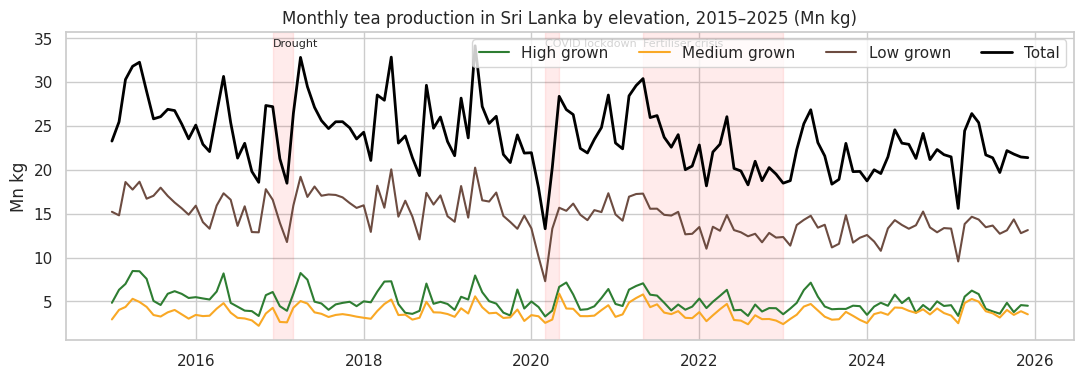

In [5]:
fig, ax = plt.subplots(figsize=(13,4))
for c, col in zip(ELEVS, ['#2E7D32','#F9A825','#6D4C41']):
    ax.plot(tea.Date, tea[c]/1e6, label=f'{c} grown', color=col)
ax.plot(tea.Date, tea.Total/1e6, color='black', lw=2, label='Total')
for (a, b, lab) in [('2016-12-01','2017-03-01','Drought'), ('2020-03-01','2020-04-30','COVID lockdown'), ('2021-05-01','2022-12-31','Fertiliser crisis')]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color='red', alpha=.08); ax.text(pd.Timestamp(a), 34, lab, fontsize=8)
ax.set_title('Monthly tea production in Sri Lanka by elevation, 2015–2025 (Mn kg)'); ax.set_ylabel('Mn kg'); ax.legend(ncol=4)
plt.show()

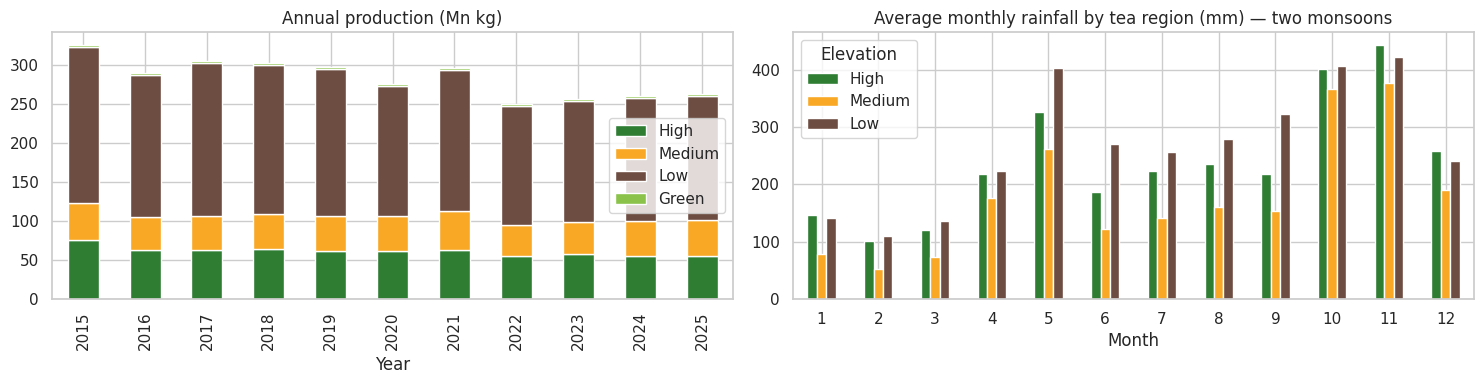

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15,4))
yearly = tea.groupby('Year')[ELEVS + ['Green']].sum()/1e6
yearly.plot(kind='bar', stacked=True, ax=axes[0], color=['#2E7D32','#F9A825','#6D4C41','#8BC34A'])
axes[0].set_title('Annual production (Mn kg)')
clim = wm[wm.Date < '2026-01-01'].assign(Month=lambda d: d.Date.dt.month).groupby(['Month','Elevation']).rain_mm.mean().unstack()[ELEVS]
clim.plot(kind='bar', ax=axes[1], color=['#2E7D32','#F9A825','#6D4C41'], rot=0)
axes[1].set_title('Average monthly rainfall by tea region (mm) - two monsoons'); plt.tight_layout(); plt.show()

In [7]:
# Does rainfall relate to production? Correlation of monthly production with weather (same month and 1-2 months before)
long0 = tea.melt(id_vars=['Date','Year','Month'], value_vars=ELEVS, var_name='Elevation', value_name='Prod').merge(wm, on=['Elevation','Date'])
long0['Prod'] /= 1e6
g0 = long0.sort_values('Date').groupby('Elevation')
long0['rain_lag1'] = g0.rain_mm.shift(1); long0['rain_lag2'] = g0.rain_mm.shift(2)
corr = long0.groupby('Elevation')[['Prod','rain_mm','rain_lag1','rain_lag2','rain_days','temp_mean','sun_hours','et0']].corr().xs('Prod', level=1)
display(corr.drop(columns='Prod').loc[ELEVS].round(2))

,rain_mm,rain_lag1,rain_lag2,rain_days,temp_mean,sun_hours,et0
Elevation,,,,,,,
High,0.10,-0.07,-0.19,0.12,0.40,0.15,0.12
Medium,0.26,-0.01,-0.24,0.31,0.34,-0.02,0.01
Low,0.22,0.07,-0.16,0.37,0.12,-0.00,-0.24


**Observations**
- Low grown tea is the majority of output; High and Medium grown are smaller and more seasonal.
- Major shocks are visible: the **2016/17 drought**, the **March 2020 COVID lockdown**, and the **2021–22 fertiliser crisis**.
- The tea-growing regions receive rain from two monsoons (South-West in May–September, North-East in December–February); high-grown areas get their main rain at a different time of year from low-grown areas.
- The correlation table shows whether production is linked to rainfall in the **same month** or **1–2 months earlier** (tea bushes respond to rain with a delay).

## 5. Feature engineering
For each elevation and month *t*:
- **Production history:** `lag1, lag2, lag3` (previous months), `lag12` (same month last year), `roll3` (3-month average)
- **Weather at that elevation's tea locations:** `rain_mm, rain_days, rain_hours, temp_mean, temp_max, temp_min, sun_hours, radiation, et0`
- **Delayed weather effects:** `rain_lag1, rain_lag2, rain_3m` (3-month total), `temp_lag1, sun_lag1`
- **Agronomic signals:** `water_balance = rain_mm − et0` (moisture surplus/deficit), `rain_anom` (rain vs normal for that month)
- **Calendar:** `month_sin, month_cos`, time index `t`, elevation one-hot

This is a **nowcast**: at the end of month *t* the weather is already measured, but official production figures are published weeks later.

**Time-based split:** train = **2016–2023** (8 years), test = **2024–2025** (2 unseen years). 2015 is used only for the lag-12 inputs.

In [8]:
def build_features(tea, wm, clim_years=range(2015, 2024)):
    long = tea.melt(id_vars=['Date','Year','Month'], value_vars=ELEVS, var_name='Elevation', value_name='Prod')
    long['Prod'] = long['Prod']/1e6
    full = wm.merge(long, on=['Elevation','Date'], how='left')          # weather rows exist before/after production
    full['Year'], full['Month'] = full.Date.dt.year, full.Date.dt.month
    full = full.sort_values(['Elevation','Date']).reset_index(drop=True)
    g = full.groupby('Elevation')
    for L in [1, 2, 3, 12]:
        full[f'lag{L}'] = g.Prod.shift(L)
    full['roll3'] = g.Prod.transform(lambda s: s.shift(1).rolling(3).mean())
    full['rain_lag1'], full['rain_lag2'] = g.rain_mm.shift(1), g.rain_mm.shift(2)
    full['rain_3m'] = full.rain_mm + full.rain_lag1 + full.rain_lag2
    full['temp_lag1'], full['sun_lag1'] = g.temp_mean.shift(1), g.sun_hours.shift(1)
    full['water_balance'] = full.rain_mm - full.et0
    normal = full[full.Year.isin(clim_years)].groupby(['Elevation','Month']).rain_mm.mean().rename('rain_normal')
    full = full.merge(normal, on=['Elevation','Month'], how='left')
    full['rain_anom'] = full.rain_mm - full.rain_normal
    full['month_sin'], full['month_cos'] = np.sin(2*np.pi*full.Month/12), np.cos(2*np.pi*full.Month/12)
    full['t'] = (full.Year - 2015)*12 + full.Month - 1
    for e in ELEVS:
        full[f'elev_{e}'] = (full.Elevation == e).astype(int)
    return full

FEATURES = ['lag1','lag2','lag3','lag12','roll3',
            'rain_mm','rain_days','rain_hours','temp_mean','temp_max','temp_min','sun_hours','radiation','et0',
            'rain_lag1','rain_lag2','rain_3m','temp_lag1','sun_lag1','water_balance','rain_anom',
            'month_sin','month_cos','t','elev_High','elev_Medium','elev_Low']
full = build_features(tea, wm)
data = full.dropna(subset=['Prod'] + FEATURES).sort_values(['Date','Elevation']).reset_index(drop=True)
train = data[data.Date < '2024-01-01']; test = data[data.Date >= '2024-01-01']
X_tr, y_tr, X_te, y_te = train[FEATURES], train.Prod, test[FEATURES], test.Prod
print(f'Model table: {len(data)} rows x {len(FEATURES)} features | train {len(train)} rows (2016–2023) | test {len(test)} rows (2024–2025)')
data[['Date','Elevation','Prod','lag1','lag12','rain_mm','rain_lag1','temp_mean','sun_hours','water_balance']].round(2).head()

Model table: 360 rows x 27 features | train 288 rows (2016–2023) | test 72 rows (2024–2025)


,Date,Elevation,Prod,lag1,lag12,rain_mm,rain_lag1,temp_mean,sun_hours,water_balance
0,2016-01-01,High,5.49,5.40,4.85,74.87,368.93,19.16,338.87,-31.36
1,2016-01-01,Low,15.91,14.88,15.21,97.17,369.10,25.79,343.97,-27.59
2,2016-01-01,Medium,3.47,3.05,2.96,34.70,223.10,23.75,335.88,-77.49
3,2016-02-01,High,5.34,5.49,6.33,107.87,74.87,19.67,320.21,-3.04
4,2016-02-01,Low,14.03,15.91,14.81,121.50,97.17,26.33,322.44,-5.27


## 6. Machine learning models - bagging, boosting, neural network, stacking
- **Random Forest / Extra Trees (bagging):** many trees trained in parallel on random samples; predictions are averaged → reduces **variance**.
- **Gradient Boosting / LightGBM / CatBoost (boosting):** trees built one after another, each fitting the remaining error → reduces **bias**.
- **ANN (MLP):** a small neural network (two hidden layers) on standardised inputs.
- **Stacking:** RF, GB, LightGBM and CatBoost predictions are combined by a Ridge meta-learner.

In [9]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

rf   = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.5, random_state=SEED)
gb   = GradientBoostingRegressor(n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEED)
lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=8, min_child_samples=8, subsample=0.8,
                     subsample_freq=1, colsample_bytree=0.7, random_state=SEED, verbose=-1)
cat  = CatBoostRegressor(iterations=700, learning_rate=0.03, depth=4, random_seed=SEED, verbose=0)
STACK = 'Stacking (RF+GB+LGBM+Cat→Ridge)'
MODELS = {
    'Random Forest':     rf,
    'Extra Trees':       ExtraTreesRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.7, random_state=SEED),
    'Gradient Boosting': gb,
    'LightGBM':          lgbm,
    'CatBoost':          cat,
    'ANN (MLP)':         TransformedTargetRegressor(
                             regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64,32), alpha=0.05,
                                                     max_iter=5000, early_stopping=False, random_state=SEED)),
                             transformer=StandardScaler()),
    STACK: StackingRegressor(estimators=[('rf',clone(rf)),('gb',clone(gb)),('lgbm',clone(lgbm)),('cat',clone(cat))],
                             final_estimator=RidgeCV(alphas=np.logspace(-3,3,20)), cv=KFold(5, shuffle=True, random_state=SEED)),
}
NAIVE = 'Seasonal Naive (lag-12)'
FAMILY = {NAIVE:'Baseline', 'Random Forest':'Bagging', 'Extra Trees':'Bagging', 'Gradient Boosting':'Boosting',
          'LightGBM':'Boosting', 'CatBoost':'Boosting', 'ANN (MLP)':'Neural network', STACK:'Stacking',
          'SARIMA':'Time series', 'Hybrid SARIMA + RF':'Hybrid'}

pred = test[['Date','Elevation','Prod']].rename(columns={'Prod':'Actual'}).reset_index(drop=True)
pred[NAIVE] = test['lag12'].values
fitted = {}
for name, m in MODELS.items():
    fitted[name] = clone(m).fit(X_tr, y_tr)
    pred[name] = fitted[name].predict(X_te)
    print(f'✓ {name}')

✓ Random Forest
✓ Extra Trees
✓ Gradient Boosting
✓ LightGBM
✓ CatBoost
✓ ANN (MLP)
✓ Stacking (RF+GB+LGBM+Cat→Ridge)


## 7. Time series model and hybrid
**SARIMA(1,0,1)(0,1,1)₁₂** is fitted separately for each elevation on 2015–2023 production only (no weather). For 2024–2025 we make one-step-ahead forecasts with the *training* parameters (no refitting on test data).

**Hybrid - SARIMA + Random Forest:** SARIMA captures trend and yearly seasonality; a Random Forest then learns SARIMA's errors **from the weather and recent production**. Final forecast = SARIMA forecast + RF correction.

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
ORDER, SORDER = (1,0,1), (0,1,1,12)
def sarima(series):
    return SARIMAX(series, order=ORDER, seasonal_order=SORDER, enforce_stationarity=False, enforce_invertibility=False)

sarima_onestep = {}
for e in ELEVS:
    s = (tea.set_index('Date')[e]/1e6).asfreq('MS')
    res = sarima(s[:'2023-12-01']).fit(disp=False)
    sarima_onestep[e] = sarima(s).filter(res.params).get_prediction(start='2016-01-01', dynamic=False).predicted_mean
    print(f'✓ SARIMA {e}:  AIC = {res.aic:.1f}')

def sarima_for(frame):
    return np.array([sarima_onestep[e].loc[d] for d, e in zip(frame.Date, frame.Elevation)])

sar_tr, sar_te = sarima_for(train), sarima_for(test)
pred['SARIMA'] = sar_te
def new_resid_rf(): return RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5, random_state=SEED)
rf_resid = new_resid_rf().fit(X_tr, y_tr.values - sar_tr)
pred['Hybrid SARIMA + RF'] = sar_te + rf_resid.predict(X_te)
pred.round(2).head()

✓ SARIMA High:  AIC = 221.4
✓ SARIMA Medium:  AIC = 146.7
✓ SARIMA Low:  AIC = 332.5


,Date,Elevation,Actual,Seasonal Naive (lag-12),Random Forest,Extra Trees,Gradient Boosting,LightGBM,CatBoost,ANN (MLP),Stacking (RF+GB+LGBM+Cat→Ridge),SARIMA,Hybrid SARIMA + RF
0,2024-01-01,High,3.48,3.55,4.67,4.82,3.91,4.20,3.93,2.91,4.17,4.60,4.27
1,2024-01-01,Low,12.57,12.34,12.53,12.62,12.12,12.56,12.08,12.16,12.28,12.18,11.80
2,2024-01-01,Medium,2.54,2.42,3.23,3.38,3.02,3.12,2.88,2.56,3.05,3.06,2.88
3,2024-02-01,High,4.42,4.19,4.88,4.86,4.67,4.80,4.69,5.26,4.75,3.97,4.06
4,2024-02-01,Low,11.83,11.36,11.81,11.82,11.35,12.11,12.19,11.31,11.90,10.53,10.36


## 8. Results - model comparison on 2024–2025 (unseen) data

In [11]:
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p),
            'MAPE %': np.mean(np.abs((y-p)/y))*100, 'R²': r2_score(y, p)}
MODEL_COLS = [c for c in pred.columns if c not in ['Date','Elevation','Actual']]
results = pd.DataFrame({m: metrics(pred.Actual, pred[m]) for m in MODEL_COLS}).T
results.insert(0, 'Family', [FAMILY[m] for m in results.index])
results = results.sort_values('RMSE')
results.round(3).style.background_gradient(subset=['RMSE','MAE','MAPE %'], cmap='RdYlGn_r')\
                      .background_gradient(subset=['R²'], cmap='RdYlGn')

,Family,RMSE,MAE,MAPE %,R²
CatBoost,Boosting,0.705000,0.530000,8.942000,0.974000
Extra Trees,Bagging,0.721000,0.544000,10.101000,0.973000
Stacking (RF+GB+LGBM+Cat→Ridge),Stacking,0.757000,0.562000,9.564000,0.970000
Hybrid SARIMA + RF,Hybrid,0.768000,0.617000,10.200000,0.969000
LightGBM,Boosting,0.792000,0.589000,10.144000,0.967000
Random Forest,Bagging,0.819000,0.581000,10.259000,0.965000
SARIMA,Time series,0.836000,0.643000,10.946000,0.963000
Gradient Boosting,Boosting,0.872000,0.628000,10.523000,0.960000
ANN (MLP),Neural network,0.890000,0.693000,11.307000,0.958000
Seasonal Naive (lag-12),Baseline,1.099000,0.791000,12.560000,0.936000


In [12]:
by_elev = pd.concat({e: pd.DataFrame({m: metrics(g.Actual, g[m]) for m in MODEL_COLS}).T
                     for e, g in pred.groupby('Elevation')}, names=['Elevation','Model']).reset_index()
print('RMSE (Mn kg) by elevation:')
display(by_elev.pivot(index='Model', columns='Elevation', values='RMSE').loc[results.index, ELEVS].round(3))
print('MAPE % by elevation:')
display(by_elev.pivot(index='Model', columns='Elevation', values='MAPE %').loc[results.index, ELEVS].round(1))

RMSE (Mn kg) by elevation:


Elevation,High,Medium,Low
CatBoost,0.506,0.540,0.970
Extra Trees,0.684,0.527,0.902
Stacking (RF+GB+LGBM+Cat→Ridge),0.569,0.560,1.041
Hybrid SARIMA + RF,0.612,0.555,1.041
LightGBM,0.609,0.588,1.079
Random Forest,0.693,0.578,1.094
SARIMA,0.762,0.537,1.108
Gradient Boosting,0.629,0.645,1.212
ANN (MLP),0.668,0.680,1.212
Seasonal Naive (lag-12),0.823,0.722,1.556


MAPE % by elevation:


Elevation,High,Medium,Low
CatBoost,9.7,11.6,5.5
Extra Trees,14.1,11.6,4.6
Stacking (RF+GB+LGBM+Cat→Ridge),11.5,11.5,5.7
Hybrid SARIMA + RF,11.6,12.4,6.6
LightGBM,12.2,12.3,5.9
Random Forest,13.6,11.5,5.7
SARIMA,14.5,11.6,6.7
Gradient Boosting,12.1,13.2,6.2
ANN (MLP),12.8,13.7,7.4
Seasonal Naive (lag-12),13.1,15.5,9.1


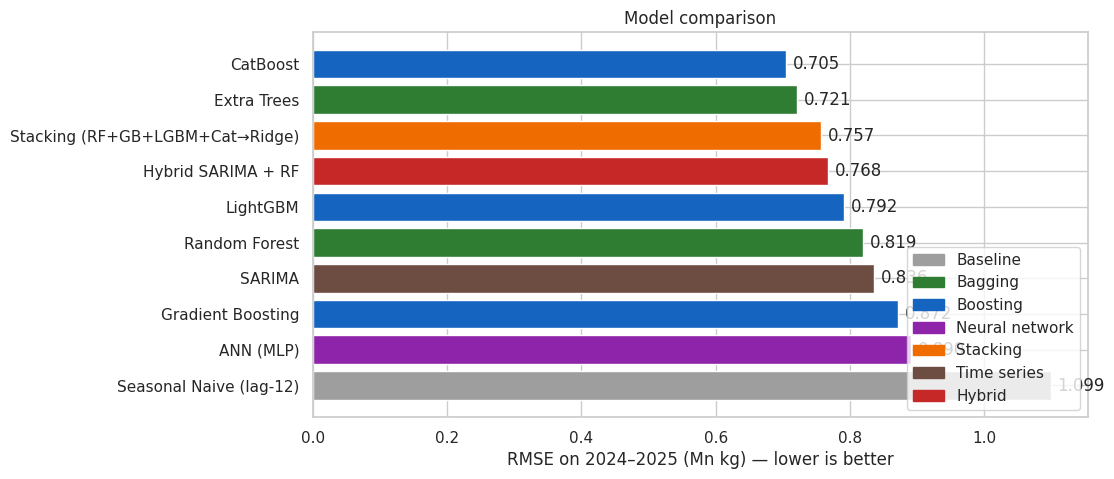

In [13]:
FAM_COL = {'Baseline':'#9E9E9E','Bagging':'#2E7D32','Boosting':'#1565C0','Neural network':'#8E24AA',
           'Stacking':'#EF6C00','Time series':'#6D4C41','Hybrid':'#C62828'}
r = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(r.index, r.RMSE, color=[FAM_COL[f] for f in r.Family])
for i, v in enumerate(r.RMSE): ax.text(v+0.01, i, f'{v:.3f}', va='center')
ax.set_xlabel('RMSE on 2024–2025 (Mn kg) - lower is better'); ax.set_title('Model comparison')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAM_COL.items()], loc='lower right'); plt.show()

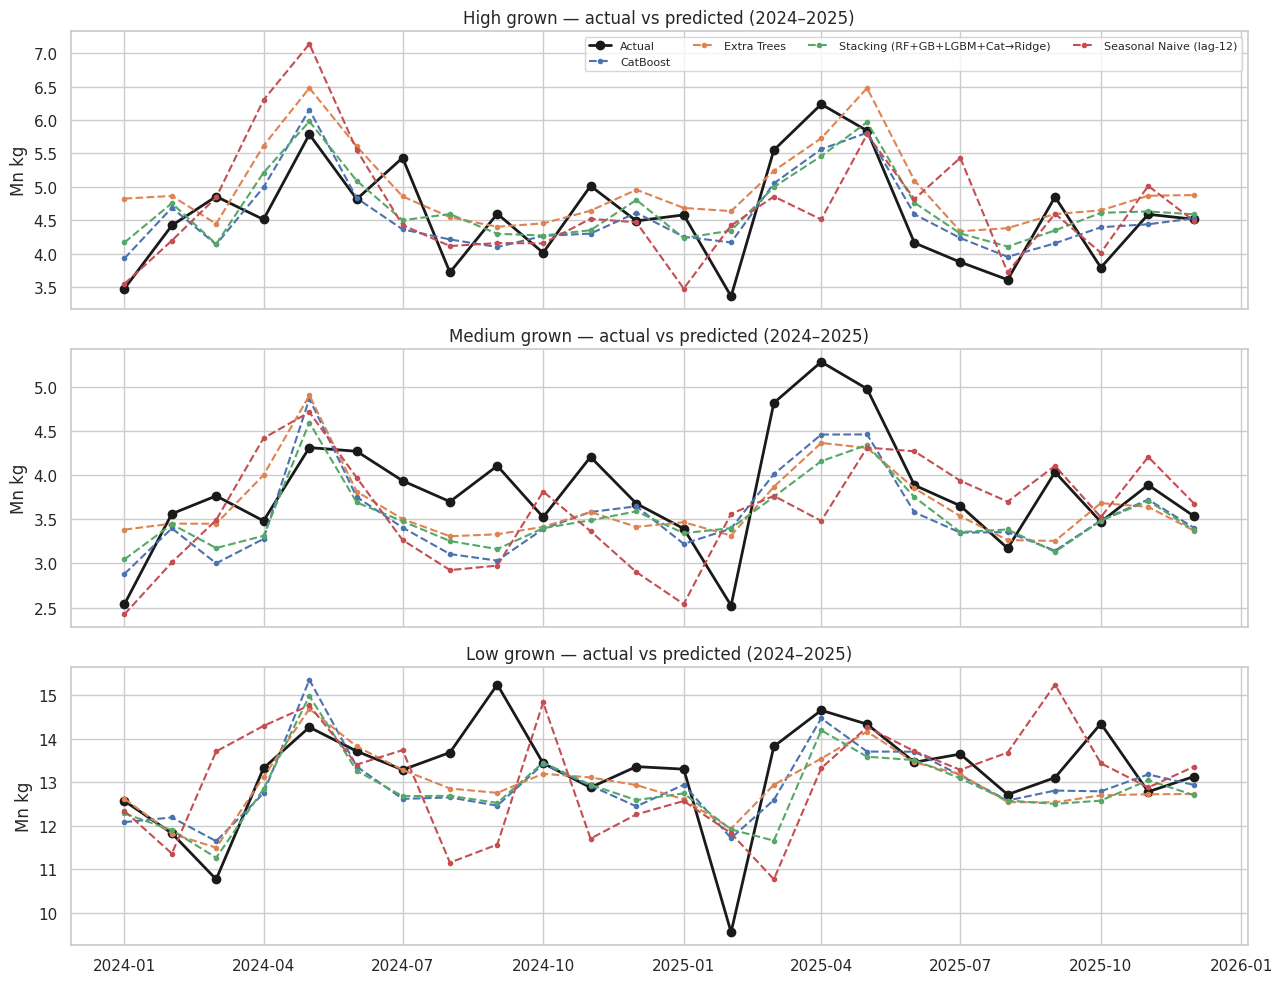

In [14]:
best = results.index[:3].tolist()
fig, axes = plt.subplots(3, 1, figsize=(13,10), sharex=True)
for ax, e in zip(axes, ELEVS):
    g = pred[pred.Elevation==e]
    ax.plot(g.Date, g.Actual, 'k-o', lw=2, label='Actual')
    for m in best + [NAIVE]:
        ax.plot(g.Date, g[m], '--', marker='.', label=m)
    ax.set_title(f'{e} grown - actual vs predicted (2024–2025)'); ax.set_ylabel('Mn kg')
axes[0].legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

## 9. Does weather help? - feature importance and a with/without-weather test
Permutation importance: how much the test RMSE increases when one feature is randomly shuffled. We also re-train the best tree models **without any weather features** to measure how much the weather adds.

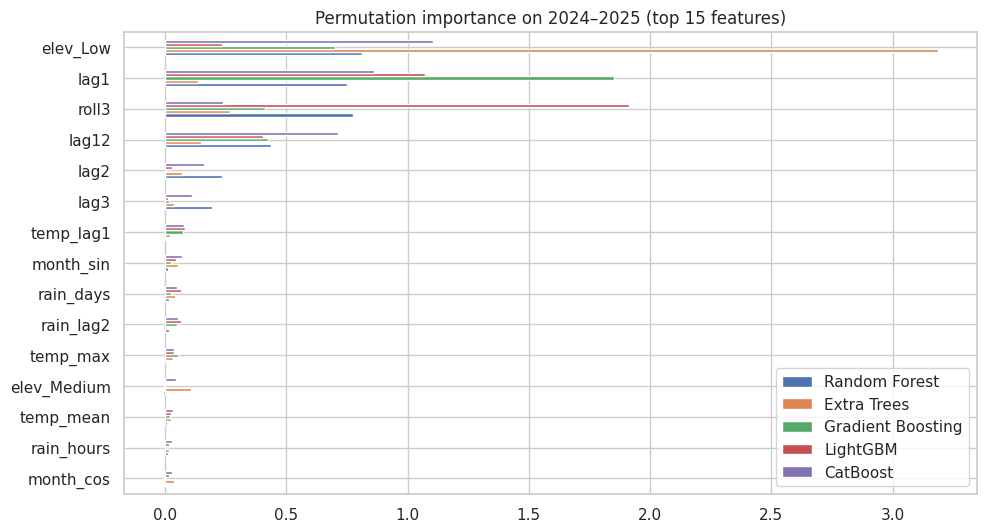

Share of total importance coming from weather features:
Random Forest         3.1 %
Extra Trees           4.3 %
Gradient Boosting     7.6 %
LightGBM              8.7 %
CatBoost             10.8 %
dtype: object


In [15]:
from sklearn.inspection import permutation_importance
IMP_MODELS = ['Random Forest','Extra Trees','Gradient Boosting','LightGBM','CatBoost']
imp_df = pd.DataFrame({n: pd.Series(permutation_importance(fitted[n], X_te, y_te, n_repeats=20, random_state=SEED,
                                    scoring='neg_root_mean_squared_error').importances_mean, index=FEATURES)
                       for n in IMP_MODELS})
top = imp_df.mean(axis=1).sort_values().index[-15:]
imp_df.loc[top].plot(kind='barh', figsize=(11,6)); plt.title('Permutation importance on 2024–2025 (top 15 features)'); plt.show()
WEATHER_FEATS = ['rain_mm','rain_days','rain_hours','temp_mean','temp_max','temp_min','sun_hours','radiation','et0',
                 'rain_lag1','rain_lag2','rain_3m','temp_lag1','sun_lag1','water_balance','rain_anom']
print('Share of total importance coming from weather features:')
print((imp_df.clip(lower=0).loc[WEATHER_FEATS].sum() / imp_df.clip(lower=0).sum() * 100).round(1).astype(str) + ' %')

In [16]:
NO_W = [f for f in FEATURES if f not in WEATHER_FEATS]
rows = []
for n in ['Random Forest','Extra Trees','Gradient Boosting','LightGBM','CatBoost']:
    p_no = clone(MODELS[n]).fit(train[NO_W], y_tr).predict(test[NO_W])
    rows.append({'Model': n, 'RMSE with weather': metrics(y_te, pred[n])['RMSE'], 'RMSE without weather': metrics(y_te, p_no)['RMSE']})
weather_test = pd.DataFrame(rows).set_index('Model')
weather_test['Improvement from weather %'] = (1 - weather_test['RMSE with weather'] / weather_test['RMSE without weather']) * 100
weather_test.round(3)

,RMSE with weather,RMSE without weather,Improvement from weather %
Model,,,
Random Forest,0.819,0.899,8.904
Extra Trees,0.721,0.832,13.363
Gradient Boosting,0.872,0.938,7.038
LightGBM,0.792,0.929,14.788
CatBoost,0.705,0.830,15.153


## 10. Final models and January 2026 forecast
All models are re-trained on **all** data (2016–2025). The January 2026 forecast uses the **actual January 2026 weather** at each tea location.

In [17]:
X_all, y_all = data[FEATURES], data.Prod
final = {name: clone(m).fit(X_all, y_all) for name, m in MODELS.items()}
# January 2026 row: production lags from 2025, weather from the real Jan 2026 observations
full26 = build_features(tea, wm)
X_next = full26[full26.Date == '2026-01-01'].set_index('Elevation').loc[ELEVS, FEATURES]
fc = pd.DataFrame(index=ELEVS)
fc[NAIVE] = X_next.lag12.values
for name, m in final.items():
    fc[name] = m.predict(X_next)
sar_next = [float(sarima((tea.set_index('Date')[e]/1e6).asfreq('MS')).fit(disp=False).forecast(1).iloc[0]) for e in ELEVS]
fc['SARIMA'] = sar_next
sar_all = sarima_for(data)
fc['Hybrid SARIMA + RF'] = np.array(sar_next) + new_resid_rf().fit(X_all, y_all.values - sar_all).predict(X_next)
fc = fc.T; fc['Total'] = fc.sum(axis=1)
print('January 2026 forecast (Mn kg), using actual January 2026 weather:')
fc.loc[results.index].round(2)

January 2026 forecast (Mn kg), using actual January 2026 weather:


,High,Medium,Low,Total
CatBoost,4.27,3.30,12.36,19.94
Extra Trees,4.52,3.09,12.56,20.17
Stacking (RF+GB+LGBM+Cat→Ridge),4.30,3.30,12.61,20.21
Hybrid SARIMA + RF,4.23,3.29,13.00,20.52
LightGBM,4.22,3.33,11.75,19.29
Random Forest,4.56,3.23,12.08,19.88
SARIMA,4.37,3.25,12.86,20.48
Gradient Boosting,4.12,3.16,11.56,18.84
ANN (MLP),3.60,3.05,12.87,19.53
Seasonal Naive (lag-12),4.58,3.40,13.30,21.27


## 11. Export the trained models for the local dashboard
Saves the final models, the merged datasets and all results into `tea_model_bundle.zip` and downloads it. Unzip it next to `app.py` so there is a folder named `tea_model_bundle`.

In [18]:
B = 'tea_model_bundle'
os.makedirs(B, exist_ok=True)
joblib.dump(final, f'{B}/ml_models.joblib', compress=3)     # 7 trained ML models (used by the "Try a prediction" tab)
results.to_csv(f'{B}/results.csv'); by_elev.to_csv(f'{B}/results_by_elevation.csv', index=False)
pred.to_csv(f'{B}/predictions_test.csv', index=False); imp_df.to_csv(f'{B}/feature_importance.csv')
weather_test.to_csv(f'{B}/weather_effect.csv'); fc.to_csv(f'{B}/forecast_2026_01.csv')
tea.to_csv(f'{B}/tea_production_monthly.csv', index=False)
full26.to_csv(f'{B}/tea_weather_monthly.csv', index=False)                       # merged model table (all months)
weather.to_csv(f'{B}/weather_daily.csv', index=False)                            # ~33k daily records
json.dump({'features': FEATURES, 'weather_features': WEATHER_FEATS, 'family': FAMILY, 'locations': LOCATIONS,
           'versions': VERSIONS, 'train': '2016-2023', 'test': '2024-2025', 'final_models_trained_on': '2016-2025',
           'created': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')}, open(f'{B}/meta.json','w'), indent=2)
shutil.make_archive(B, 'zip', B)
print(sorted(os.listdir(B))); print('Zip size: %.1f MB' % (os.path.getsize(B+'.zip')/1e6))
print('Library versions to install locally:', VERSIONS)
try:
    from google.colab import files; files.download(B+'.zip')
except Exception as e:
    print('Download it from the Files panel on the left:', e)

['feature_importance.csv', 'forecast_2026_01.csv', 'meta.json', 'ml_models.joblib', 'predictions_test.csv', 'results.csv', 'results_by_elevation.csv', 'tea_production_monthly.csv', 'tea_weather_monthly.csv', 'weather_daily.csv', 'weather_effect.csv']
Zip size: 10.3 MB
Library versions to install locally: {'scikit-learn': '1.6.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'statsmodels': '0.15.0'}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Interpretation and conclusion

### Which model won?
On the two unseen test years, 2024 and 2025, **CatBoost was the best model: RMSE 0.705 Mn kg, MAPE 8.9%, R² 0.974**. That is about **36% lower error than the seasonal naive baseline** (RMSE 1.099), which simply repeats last year's value. It was followed by **Extra Trees** at 0.721, **Stacking** at 0.757 and the **Hybrid SARIMA + RF** at 0.768. LightGBM scored 0.792, Random Forest 0.819, SARIMA 0.836, Gradient Boosting 0.872 and the ANN 0.890. **All nine models beat the naive baseline.**

By elevation:
- **High grown:** CatBoost was best, RMSE 0.506 against 0.823 for the baseline.
- **Medium grown:** Extra Trees was best at 0.527, with SARIMA at 0.537 and CatBoost at 0.540 close behind.
- **Low grown:** Extra Trees was best at 0.902, then CatBoost at 0.970, against 1.556 for the baseline.

### Does the weather help? Yes.
We re-trained each tree model **without any weather features** and compared the test error:
- CatBoost improved by **15.2%** with weather, LightGBM by **14.8%**, Extra Trees by **13.4%**, Random Forest by **8.9%** and Gradient Boosting by **7.0%**.
- The hybrid shows the same thing: SARIMA alone, which uses no weather, scored 0.836, but adding a Random Forest that learns SARIMA's errors **from the weather** brought it down to 0.768, about 8% better.

The weather features that matter most are **last month's temperature (`temp_lag1`), the number of rain days, and rainfall two months earlier (`rain_lag2`)**. This matches tea agronomy: a tea bush responds to rain and warmth with a **delay of one to two months**, because new shoots take weeks to grow before they are plucked. The correlations in the EDA support this. **High grown** production rises in warmer months (r = 0.40), because cold limits growth at high altitude. **Low grown** production rises with more rain days (r = 0.37) and falls when evapotranspiration is high (r = −0.24), that is, during hot, dry spells.

Production history is still the strongest signal: `lag1`, `roll3` and `lag12` rank highest, and weather adds 3 to 11% of total importance on top of it. So weather does not replace the time-series pattern; it **corrects** it in unusual months, such as droughts or very wet spells.

### Why do the models behave this way?
1. **Boosting with regularisation won.** With eight years of training data and 27 features, CatBoost could learn the small, non-linear weather effects. Its ordered boosting and symmetric trees reduce overfitting, which matters with only 288 training rows. CatBoost also used the weather the most: 10.8% of its importance came from weather features.
2. **Bagging stayed strong and stable.** Extra Trees was second overall and best for Medium and Low grown. Averaging many random trees reduces variance, which suits noisy monthly data.
3. **Plain Gradient Boosting and LightGBM relied too heavily on one input.** Feature importance shows Gradient Boosting depended mostly on `lag1` and LightGBM on `roll3`. When one month was unusual, the next prediction followed it too closely.
4. **Stacking came third.** It beat most of its own base models but not CatBoost, because its four base learners are all tree models on the same features, so their errors overlap.
5. **SARIMA dropped to mid-table.** It only sees past production, so it cannot react to weather. With weather added through the hybrid, it improved.
6. **The ANN improved but is still behind the trees.** It now beats the baseline clearly, 0.890 against 1.099, but about 300 rows is still small for a neural network.

### Limitations and future work
- Weather comes from the ERA5 reanalysis via Open-Meteo, a modelled grid, not rain gauges on the estates. One or two towns per tea region also cannot capture every estate's micro-climate.
- Production figures are the Tea Board's monthly data as published by Forbes & Walker, which may differ slightly from later revised figures.
- The model is a **nowcast**: it uses the weather of the month being predicted. For true forecasting, the next step is to feed it weather *forecasts*.
- Other drivers are not included: fertiliser prices and supply, the labour situation, auction prices, and El Niño indices.

### Conclusion
Adding the weather of each tea-growing region makes every model more accurate, by up to 15%. **CatBoost, a boosting model, gave the best overall forecast**, with an average error under 9%, and **Extra Trees, a bagging model, was best for Medium and Low grown tea**. Combining time series with machine learning in the SARIMA + RF hybrid also worked, by letting the weather correct SARIMA's seasonal forecast.